# Анализ и прогнозирование временных рядов методами искусственного интеллекта

## **Практическая работа 4. Матричный профиль. Поиск примитивов на его основе.**

Смените рабочую директорию с помощью команды `chdir()`. Для этого передайте этой команде свой путь до каталога, в котором содержатся материалы четвертой практической работы. После выполнения этой команды все последующие операции с файлами и каталогами будут производиться относительно указанного каталога.

In [1]:
import os
import sys
from pathlib import Path

candidates = [Path.cwd(), Path.cwd() / 'practice' / '04 Matrix profile',
              Path(r'C:\Users\artem\2026-Artemov-TimeSeriesCourse\practice\04 Matrix profile')]
practice_dir_path = next(p for p in candidates if (p / 'datasets' / 'part2' / 'pamap.csv').is_file())
os.chdir(practice_dir_path)
if str(practice_dir_path) not in sys.path:
    sys.path.insert(0, str(practice_dir_path))
print('Рабочая папка:', Path.cwd())

Рабочая папка: C:\Users\artem\2026-Artemov-TimeSeriesCourse\practice\04 Matrix profile


Выполните команды, которые автоматически перезагружают все импортированные модули при их изменении.

In [2]:
%load_ext autoreload
%autoreload 2

Импортируйте библиотеки и модули, необходимые для реализации практической работы 4.

In [3]:
import importlib.util
import subprocess

if importlib.util.find_spec('stumpy') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'stumpy'])

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import numba

from modules.plots import plot_ts, plot_motifs, plot_discords, plot_segmentation
from modules.mp import compute_mp
from modules.motifs import top_k_motifs
from modules.discords import top_k_discords

numba.set_num_threads(min(4, numba.config.NUMBA_NUM_THREADS))
plt.style.use('default')
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white',
                     'savefig.facecolor': 'white', 'savefig.transparent': False,
                     'font.size': 10, 'figure.dpi': 110})

## **Часть 1.** Матричный профиль. Поиск мотивов и диссонансов.

### **Задача 1.**
Загрузите временной ряд, который содержит данные о почасовом потреблении электроэнергии некоторого итальянского города, снимаемые в течение 3 лет, начиная с 1 января 1995 года.

In [5]:
ts_url = './datasets/part1/italianpowerdemand.csv'
ts = pd.read_csv(ts_url, header=None).squeeze().to_numpy(dtype=np.float64)
assert ts.ndim == 1 and np.isfinite(ts).all()
print(f'Электропотребление: {ts.size} отсчетов')

Электропотребление: 29931 отсчетов


Визуализируйте временной ряд, используя функцию `plot_ts()` из модуля *plot.py*.

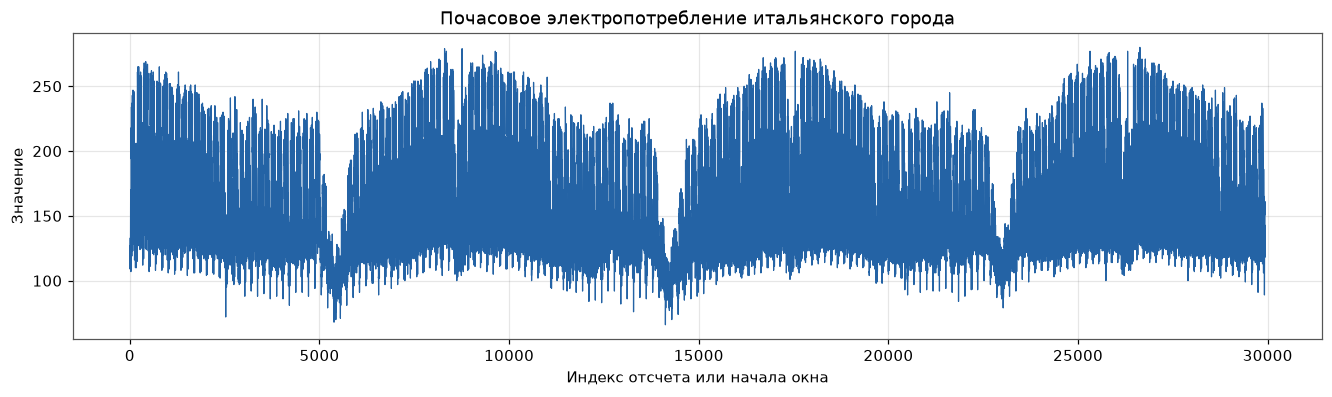

In [6]:
plot_ts(ts, 'Почасовое электропотребление итальянского города')

Анализ временных рядов на основе матричного профиля осуществляет библиотека [stumpy](https://stumpy.readthedocs.io/en/latest/index.html). Напишите функцию `compute_mp()` в модуле *mp.py*, которая вычисляет матричный профиль временного ряда на основе выбранной вами функции из библиотеки *stumpy*.

In [7]:
m = 165
excl_zone = int(np.ceil(m / 2))
mp = compute_mp(ts, m, exclusion_zone=excl_zone)
power_mp = mp
print(f"Длина профиля: {len(mp['mp'])}; окно: {m}; радиус исключения: {excl_zone}")
assert len(mp['mp']) == len(ts) - m + 1

Длина профиля: 29767; окно: 165; радиус исключения: 83


Визуализируйте найденный матричный профиль ряда.

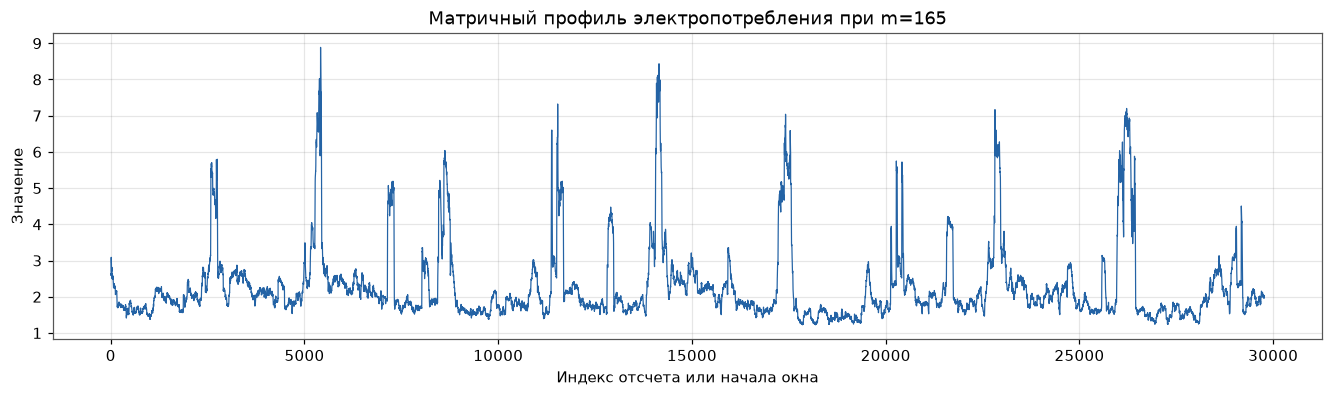

In [8]:
plot_ts(mp['mp'], 'Матричный профиль электропотребления при m=165')

### **Задача 2.**
Выполните поиск top-$k$ мотивов в исходном временном ряде на основе построенного матричного профиля. Для этого реализуйте самостоятельно функцию `top_k_motifs()` в модуле *motifs.py*. Среди найденных мотивов не должно быть тривиальных совпадений, поэтому в `top_k_motifs()` добавьте вызов функции `apply_exclusion_zone()` из модуля *utils.py*.

In [9]:
top_k = 6
motifs = top_k_motifs(mp, top_k=top_k)
assert len(motifs['indices']) == top_k
motifs_table = pd.DataFrame({
    'Ранг': np.arange(1, len(motifs['indices']) + 1),
    'Начало первого окна': [pair[0] for pair in motifs['indices']],
    'Начало второго окна': [pair[1] for pair in motifs['indices']],
    'Расстояние': motifs['distances'],
})
display(motifs_table)

,Ранг,Начало первого окна,Начало второго окна,Расстояние
0,1,17852,18188,1.226625
1,2,18539,27276,1.235633
2,3,19168,28073,1.245558
3,4,18623,18791,1.325500
4,5,17764,26837,1.348673
5,6,1020,9757,1.375152


Выполните визуализацию найденных top-$k$ мотивов с помощью функции `plot_motifs()` из *plots.py*.

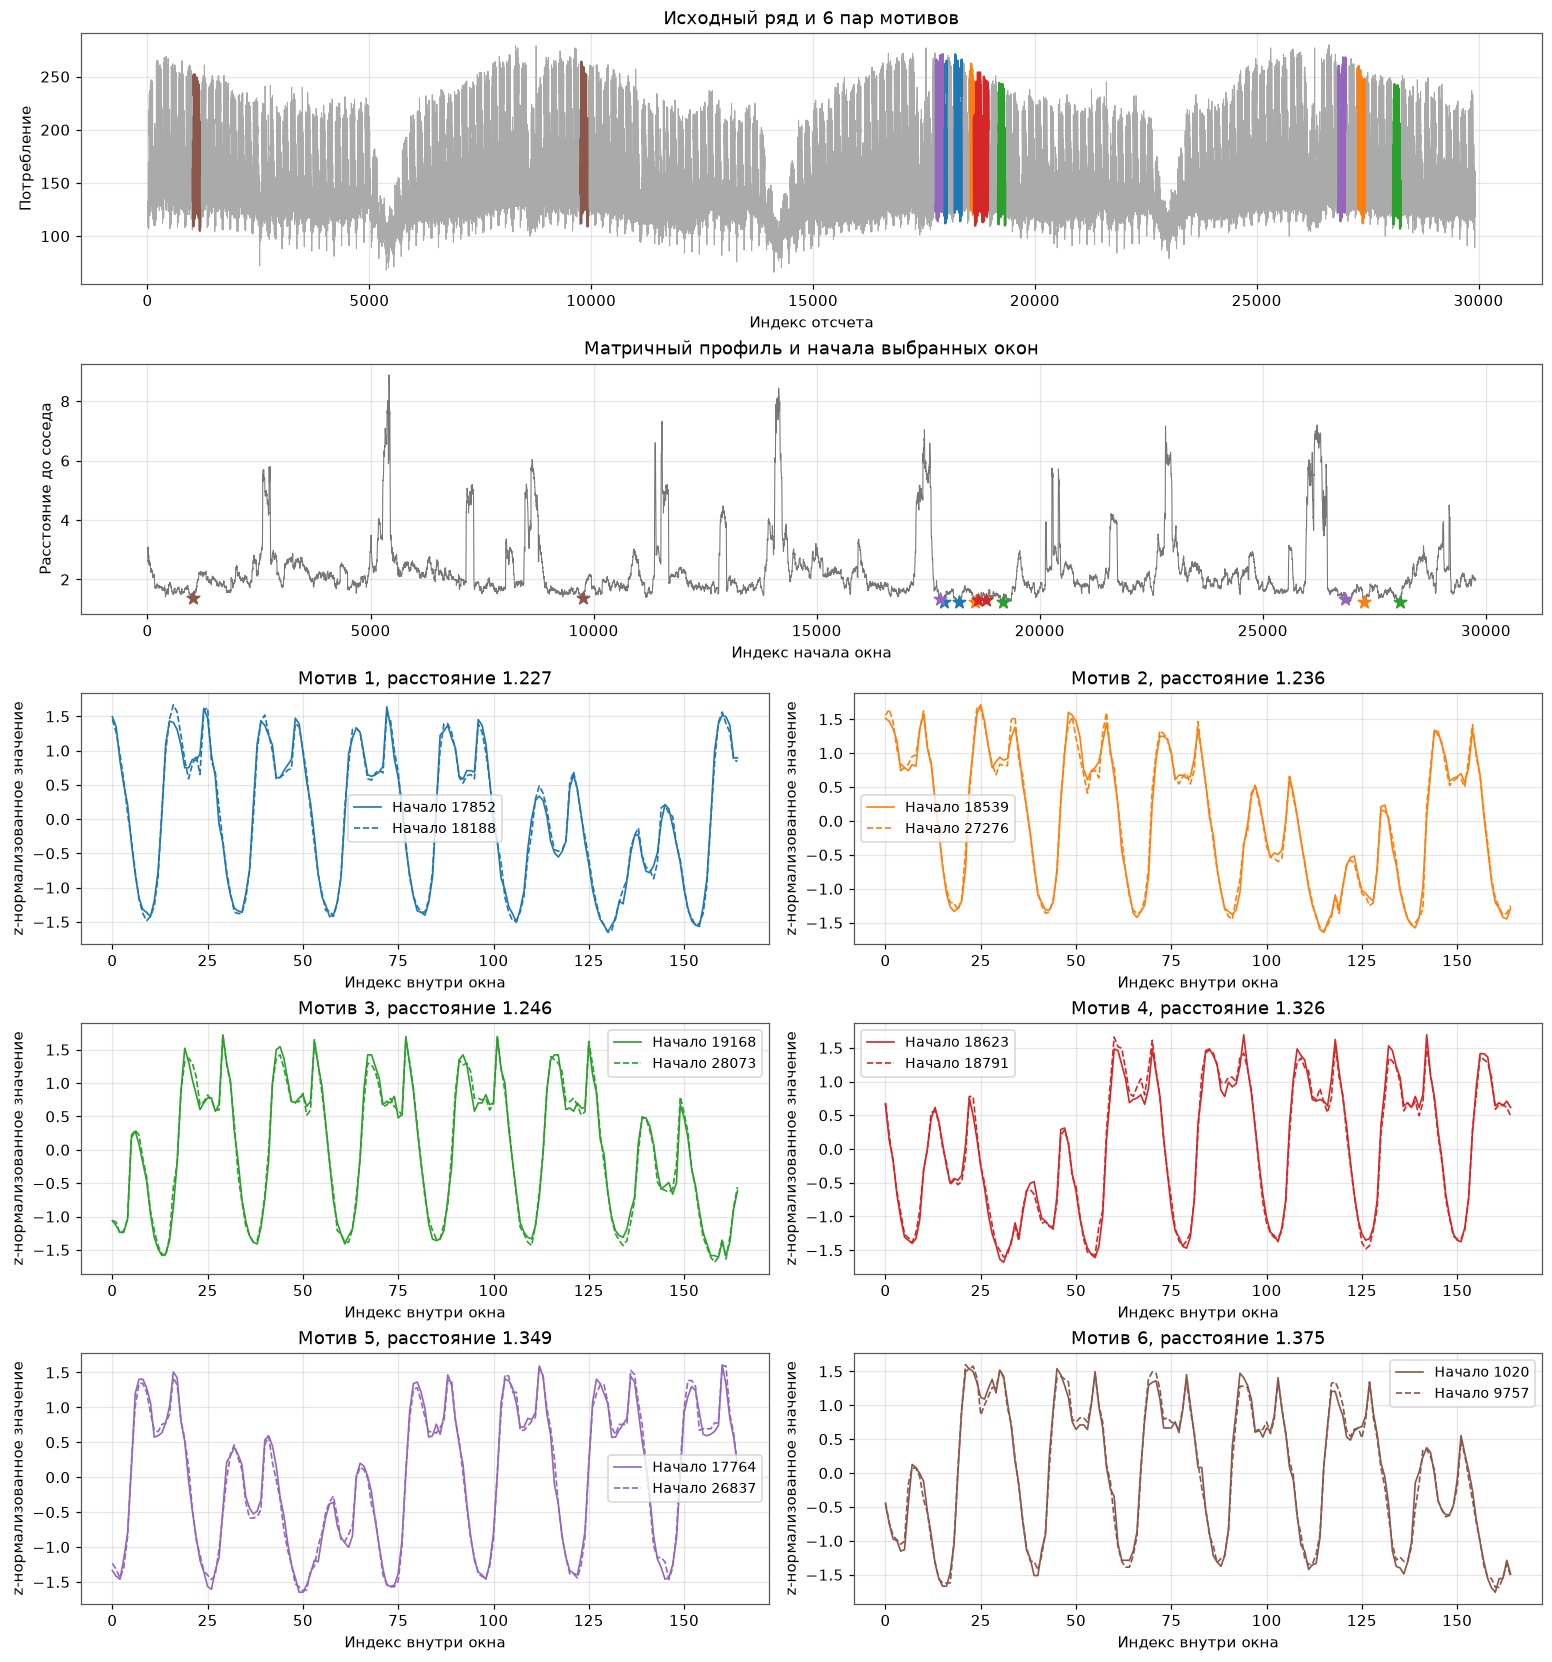

In [10]:
plot_motifs(mp, motifs)

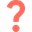
Проанализируйте и изложите содержательный смысл полученных результатов.

Найдены шесть пар повторяющихся фрагментов электропотребления длиной 165 часов
(6 суток и 21 час). Малые значения матричного профиля соответствуют окнам, для
которых найден очень похожий фрагмент в другой части ряда. Перед сравнением
окна z-нормализуются, поэтому сравнивается форма потребления, а не его уровень.

На верхнем графике одинаковым цветом выделены два вхождения каждой пары,
на профиле отмечены их начала. На нижних графиках нормализованные окна
совмещены: близость кривых показывает сходство формы. Периодическое потребление
объясняет повторяемость рисунка; без календарной разметки нельзя приписать
каждой паре конкретный тип дня. Зона исключения радиусом 83 отсчета убирает
тривиальные соседние копии вокруг обоих вхождений. Частичное перекрытие окон
при такой зоне допускается. Отбор не изменяет исходный матричный профиль.

Наиболее похожая пара начинается с индексов 17852 и 18188: расстояние около 1,227, между началами 336 часов, то есть две недели. Четвертая пара имеет сдвиг 168 часов, то есть одну неделю. Это согласуется с недельной повторяемостью формы потребления. Всего расстояния шести пар лежат примерно от 1,227 до 1,375.

### **Задача 3.**
Реализуйте самостоятельно функцию `top_k_discords()` в модуле *discords.py*, предназначенную для поиска top-$k$ диссонансов во временном ряде на основе матричного профиля. Чтобы исключить попадание тривиальных совпадений в результирующее множество диссонансов воспользуйтесь функцией `apply_exclusion_zone()` из модуля *utils.py*.

Загрузите временной ряд *nyc_taxi.csv* из директории *./datasets/part1/*, содежащий данные о среднем числе пассажиров NY такси за осень 2014 года.

Такси NY: 10320 отсчетов, от 2014-07-01 00:00:00 до 2015-01-31 23:30:00


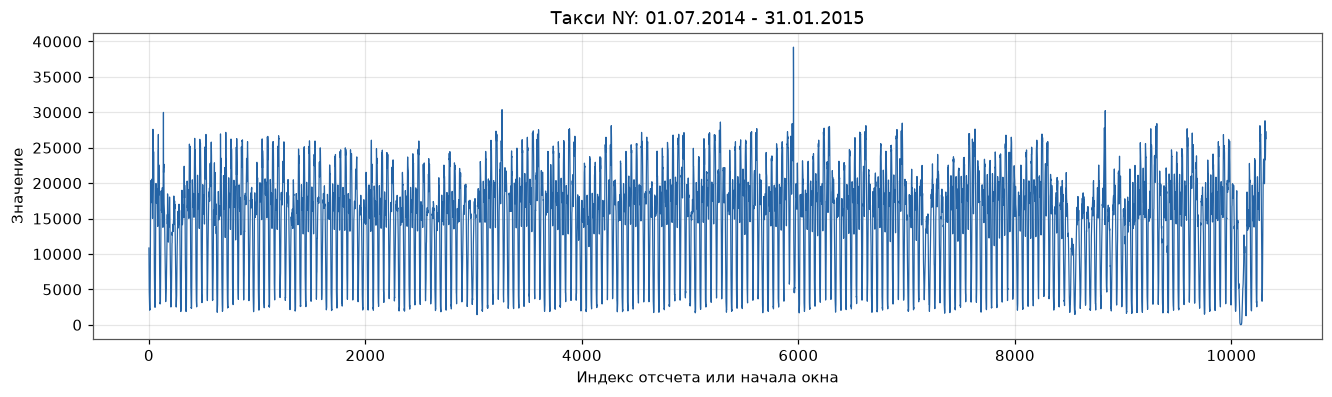

In [11]:
ts_url = './datasets/part1/nyc_taxi.csv'
taxi_frame = pd.read_csv(ts_url, parse_dates=['timestamp'])
taxi_timestamps = taxi_frame['timestamp']
ts = taxi_frame['value'].to_numpy(dtype=np.float64)
assert np.isfinite(ts).all()
print(f'Такси NY: {len(ts)} отсчетов, от {taxi_timestamps.iloc[0]} до {taxi_timestamps.iloc[-1]}')
plot_ts(ts, f"Такси NY: {taxi_timestamps.iloc[0]:%d.%m.%Y} - {taxi_timestamps.iloc[-1]:%d.%m.%Y}")

In [12]:
m = 96
excl_zone = int(np.ceil(m / 2))
mp = compute_mp(ts, m, exclusion_zone=excl_zone)
taxi_mp = mp
print(f"Длина профиля: {len(mp['mp'])}; окно: {m}; радиус исключения: {excl_zone}")

Длина профиля: 10225; окно: 96; радиус исключения: 48


In [13]:
top_k = 15
discords = top_k_discords(mp, top_k=top_k)
assert len(discords['indices']) == top_k
discords_table = pd.DataFrame({
    'Ранг': np.arange(1, len(discords['indices']) + 1),
    'Начало окна': discords['indices'],
    'Дата начала': [taxi_timestamps.iloc[i] for i in discords['indices']],
    'Расстояние до соседа': discords['distances'],
    'Начало ближайшего соседа': discords['nn_indices'],
})
display(discords_table)

,Ранг,Начало окна,Дата начала,Расстояние до соседа,Начало ближайшего соседа
0,1,9985,2015-01-25 00:30:00,7.676119,9650
1,2,10048,2015-01-26 08:00:00,7.528591,8469
2,3,8784,2014-12-31 00:00:00,6.073551,9263
3,4,10097,2015-01-27 08:30:00,5.111043,257
4,5,8837,2015-01-01 02:30:00,4.492294,5618
5,6,5868,2014-10-31 06:00:00,4.241044,6204
6,7,105,2014-07-03 04:30:00,4.165698,7112
7,8,9651,2015-01-18 01:30:00,3.947103,8307
8,9,8410,2014-12-23 05:00:00,3.736814,8361
9,10,5954,2014-11-02 01:00:00,3.706804,5282


Выполните визуализацию найденных top-$k$ диссонансов.

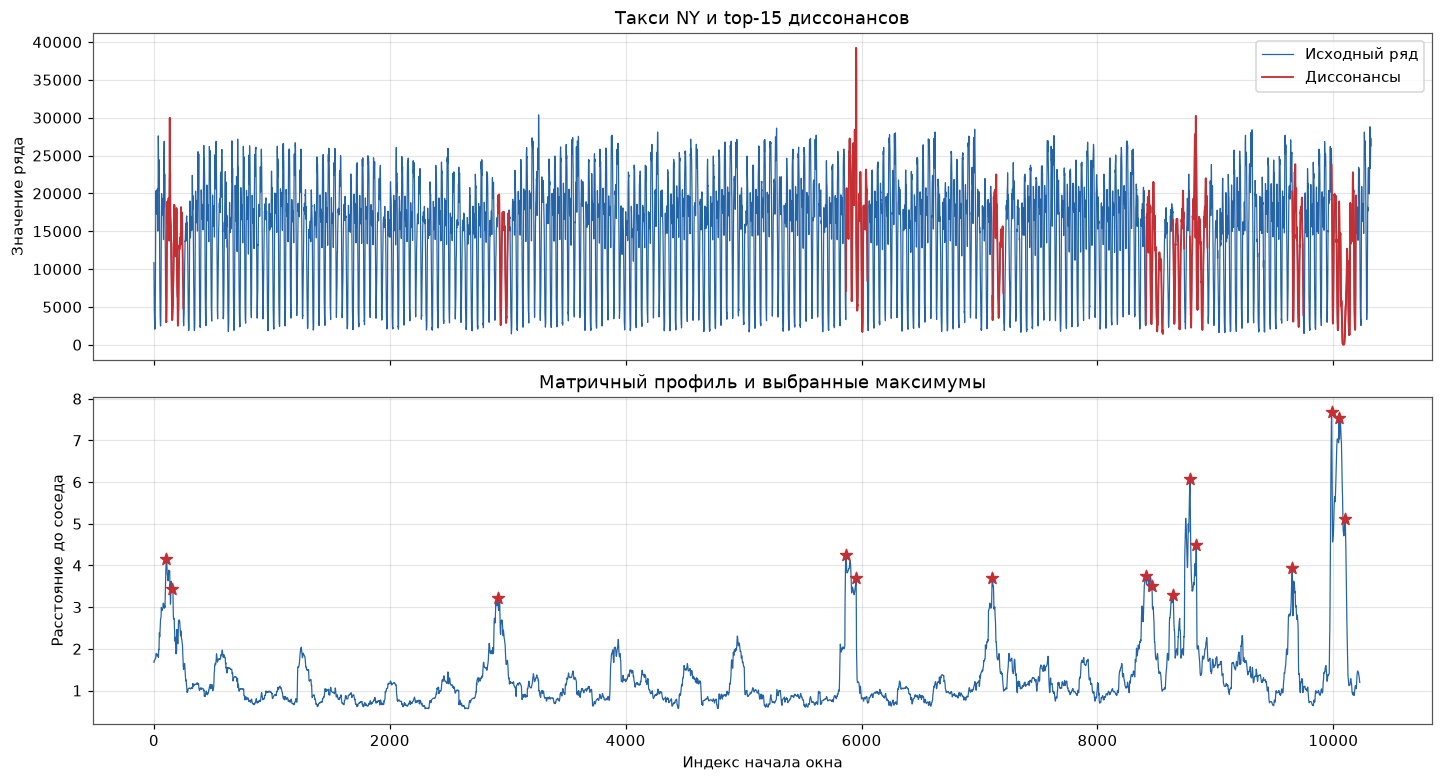

In [14]:
plot_discords(mp, discords)

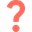
Проанализируйте и изложите содержательный смысл полученных результатов.

Выбраны 15 окон с наибольшим расстоянием до ближайшего допустимого соседа.
Окно длиной 96 получасовых отсчетов охватывает двое суток. На верхнем графике
красным выделены необычные фрагменты, на нижнем отмечены соответствующие
максимумы матричного профиля. Чем выше максимум, тем хуже для окна находится
похожий фрагмент. При этом аномалия определяется формой окна, а не просто
высоким или низким значением отдельной точки.

Даты и расстояния приведены в таблице. Радиус исключения 48 отсчетов
не позволяет выбирать соседние начала ближе этого расстояния, однако окна
длиной 96 могут частично перекрываться. Поэтому 15 окон не обязательно
означают 15 независимых событий. Набор фактически охватывает июль 2014 года - январь 2015 года,
что видно из дат файла, хотя в условии упомянута осень. Причину каждого
изменения нельзя установить только по профилю без дополнительных данных.

Наибольшие значения профиля, около 7,676 и 7,529, относятся к окнам с началами 25 и 26 января 2015 года. Заметно выделяется и окно, начинающееся 31 декабря 2014 года. Эти даты указывают, какие периоды следует изучить подробнее; сами по себе они не доказывают причину аномалии.

## **Часть 2.** Сегментация повторяющихся активностей.

### **Задача 4.**

Загрузите временной ряд PAMAP *pamap.csv* из директории *./datasets/part2/*, представляющий собой показания закрепленного на человеке виброакселерометра. Данный ряд включает показания, снятые при выполнении человеком трех видов физической активности: ходьба, подъем по лестнице и спуск по лестнице. Необходимо сегментировать временной ряд на основе его матричного профиля для определения того, когда человек шел и когда поднимался/спускался. Поскольку подъем и спуск по лестнице – это схожие действия, поэтому будем считать, что это одна активность.  

In [15]:
ts_url = './datasets/part2/pamap.csv'
pamap_raw = pd.read_csv(ts_url, header=None).squeeze().to_numpy(dtype=np.float64)
missing_count = int(np.isnan(pamap_raw).sum())
ts = pd.Series(pamap_raw).interpolate(limit_direction='both').to_numpy(dtype=np.float64)
assert len(ts) == len(pamap_raw) and np.isfinite(ts).all()
print(f'PAMAP: {len(ts)} отсчетов; заполнено пропусков: {missing_count}')
print('Пропуски заполнены линейной интерполяцией без удаления строк и без использования меток.')

PAMAP: 31000 отсчетов; заполнено пропусков: 5
Пропуски заполнены линейной интерполяцией без удаления строк и без использования меток.


Визуализируйте временной ряд PAMAP.

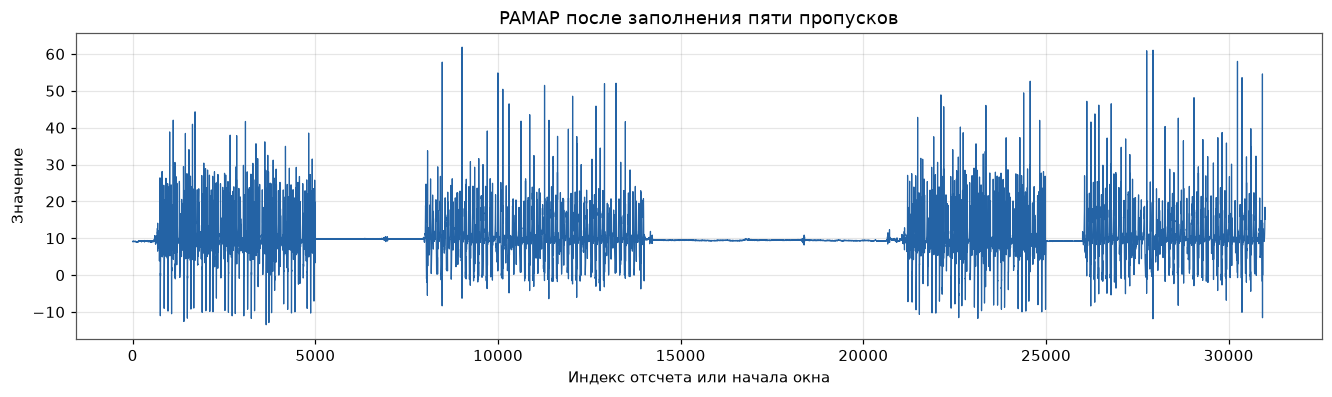

In [16]:
plot_ts(ts, 'PAMAP после заполнения пяти пропусков')

Найдите и визуализируйте матричный профиль временного ряда.

In [17]:
m = 100
excl_zone = m
mp = compute_mp(ts, m, exclusion_zone=excl_zone)
pamap_mp = mp
print(f"Длина профиля: {len(mp['mp'])}; окно: {m}; радиус исключения: {excl_zone}")

Длина профиля: 30901; окно: 100; радиус исключения: 100


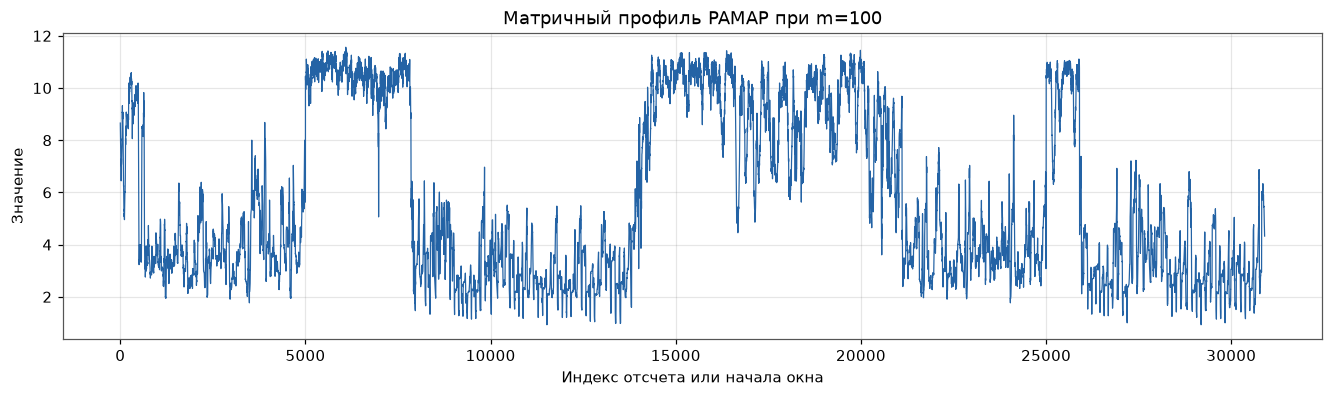

In [18]:
plot_ts(mp['mp'], 'Матричный профиль PAMAP при m=100')

Вычислите порог по формуле, которая представлена в презентации [04 Matrix profile.pdf](https://github.com/mzym/TimeSeriesCourse/blob/main/slides/04%20Matrix%20profile.pdf).

In [19]:
# Формула со слайда 27: RA = {i: P[i] < alpha * (min(P) + max(P))}.
# alpha фиксируется до загрузки меток и не подбирается по accuracy.
alpha = 0.5
profile = mp['mp']
assert np.isfinite(profile).all()
threshold = alpha * (profile.min() + profile.max())
predicted_labels = (profile < threshold).astype(np.int64)  # 0: ходьба, 1: лестница
window_centers = np.arange(len(profile)) + m // 2
print(f'alpha={alpha}; min(P)={profile.min():.6f}; max(P)={profile.max():.6f}')
print(f'Порог: {threshold:.6f}; окон лестницы: {predicted_labels.sum()} из {len(profile)}')

alpha=0.5; min(P)=0.928973; max(P)=11.563415
Порог: 6.246194; окон лестницы: 19511 из 30901


Выполните визуализацию результатов сегментации повторяющихся активностей.

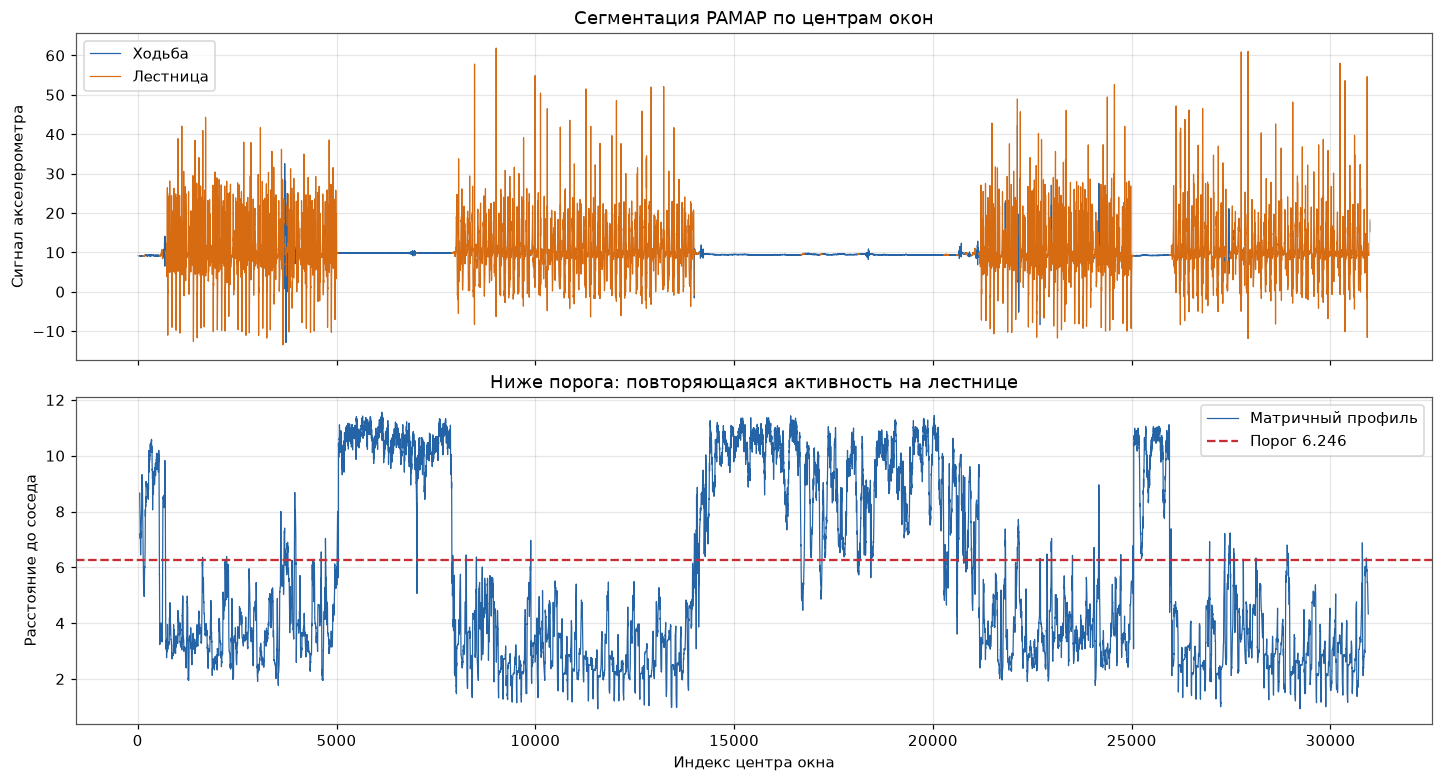

In [20]:
plot_segmentation(mp, threshold)

Загрузите истинную разметку временного ряда PAMAP *pamap_labels.csv*, где 0 означает ходьбу, 1 – подъем по лестнице, 2 – спуск с лестницы. Вычислите точность по метрике accuracy, сравнив полученные результаты по основе матричного профиля с истинной разметкой.

In [21]:
labels_url = './datasets/part2/pamap_labels.csv'

labels = pd.read_csv(labels_url, header=None).squeeze().to_numpy()

Accuracy: 0.9467 (94.67%)
Доля самого частого класса для сравнения: 64.40%
Проверено 30901 центров окон; первые 50 и последние 49 точек не оцениваются.


Предсказанный класс,Ходьба,Лестница
Истинный класс,,
Ходьба,10372,628
Лестница,1018,18883


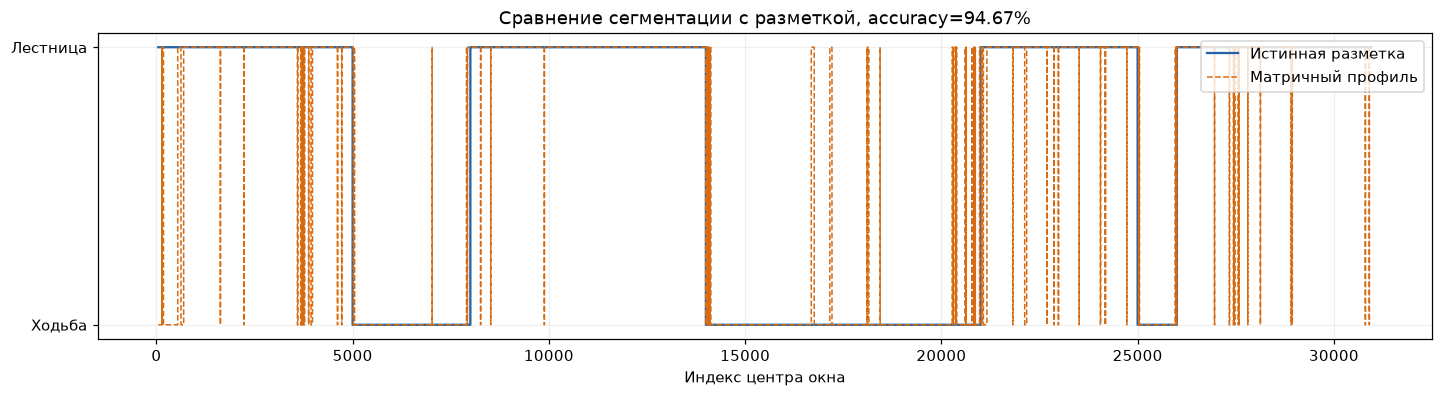

In [22]:
assert len(labels) == len(ts)
assert set(np.unique(labels)) <= {0, 1, 2}
binary_labels = (labels != 0).astype(np.int64)  # Подъем и спуск объединяются.
true_labels = binary_labels[window_centers]
accuracy = float(np.mean(predicted_labels == true_labels))
baseline_accuracy = float(np.bincount(true_labels).max() / len(true_labels))
confusion = pd.crosstab(
    pd.Series(true_labels, name='Истинный класс'),
    pd.Series(predicted_labels, name='Предсказанный класс'),
).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
print(f'Accuracy: {accuracy:.4f} ({accuracy:.2%})')
print(f'Доля самого частого класса для сравнения: {baseline_accuracy:.2%}')
print(f'Проверено {len(true_labels)} центров окон; первые {m // 2} и последние {len(ts) - 1 - window_centers[-1]} точек не оцениваются.')
display(confusion.rename(index={0: 'Ходьба', 1: 'Лестница'}, columns={0: 'Ходьба', 1: 'Лестница'}))

fig, ax = plt.subplots(figsize=(13, 3.5), layout='constrained')
ax.step(window_centers, true_labels, where='mid', color='#2463A5', label='Истинная разметка', linewidth=1.5)
ax.step(window_centers, predicted_labels, where='mid', color='#D66B12', linestyle='--', label='Матричный профиль', linewidth=1)
ax.set(yticks=[0, 1], yticklabels=['Ходьба', 'Лестница'], xlabel='Индекс центра окна',
       title=f'Сравнение сегментации с разметкой, accuracy={accuracy:.2%}')
ax.legend(loc='upper right')
ax.grid(alpha=0.2)
plt.show()

### Вывод по сегментации

Подъем и спуск объединены в класс «лестница». Окна с профилем ниже порога относятся к повторяющейся активности на лестнице, остальные к ходьбе. Метка окна сопоставлена с истинной меткой в его центре: профиль короче исходного ряда на m-1 отсчетов, поэтому края без центров окон не входят в accuracy.

Сравнение показывает качество простого порогового правила на этой записи. Часть ошибок возникает около границ, где окно содержит две активности. Короткие ложные переключения встречаются и внутри сегментов: один порог не разделяет все окна без ошибок. Это не независимая проверка на новых людях и не обучение классификатора по меткам. Параметры m=100, радиус исключения 100 и alpha=0,5 зафиксированы до сравнения с разметкой.


Получен порог 6,246 и accuracy 94,67% на 30901 центре окон. Для сравнения, постоянный прогноз самого частого класса дал бы 64,40%. Правильно определены 10372 окна ходьбы и 18883 окна лестницы; ошибки составили 628 и 1018 окон соответственно.

## **Чaсть 3.** Casy Study: Раскрытие краж электричества подменой счетчиков (meter-swapping detection).


### **Задача 5.**

Рассмотрим практическое применение использования матричного профиля для решения задачи, связанной с раскрытием краж электричества путем подмены счетчиков.

Загрузите временные ряды из директории *./datasets/part3/*, которые были выбраны случайным образом из набора данных (House 1, 2, 3, 4 и 11), содержащего данные потребления электроэнергии 20 жилых домов в Великобритании с 1 января по 23 декабря 2014 года.

In [ ]:
path = './datasets/part3/'

house_idx = [1, 2, 3, 4, 11]

filenames = [f"House{i}.csv" for i in house_idx]

consumptions = {}
for house in filenames:
    consumptions[house[:-4]] = pd.read_csv(os.path.join(path, house), header=None, index_col=0)
    consumptions[house[:-4]].index = pd.to_datetime(consumptions[house[:-4]].index, dayfirst=True)

Далее смоделируем событие замены счетчика. Для этого каждый временной ряд разделим на две части: "Head" (до 1 октября) и "Tail" (после 1 октября). После чего выберем случайным образом 2 временных ряда (например, House1 и House11) и поменяем местами их "Tail" части.

In [ ]:
cutoff = pd.to_datetime('2014-10-01')
heads, tails = heads_tails(consumptions, cutoff, house_idx)

#swap Heads and Tails of 1 and 11
swap1, swap2 = 1, 11
consumptions[f'House{swap1}'] = heads[f'H_{swap1}'].append(tails[f'T_{swap2}'])
consumptions[f'House{swap2}'] = heads[f'H_{swap2}'].append(tails[f'T_{swap1}'])
heads, tails = heads_tails(consumptions, cutoff, house_idx)

Визуализируйте исходные временные ряды и параллельную оси OY прямую, которая делит временные ряды на "Head" и "Tail" части.

In [ ]:
plot_consumptions_ts(consumptions, cutoff, house_idx)

Чтобы найти переставленную пару временных рядов, выполним следующее. Сначала составим временные ряды $H_i$ из всевозможных комбинаций "Head" и "Tail" частей исходных временных рядов $T_K$, где $1 \leq i \leq |T|^2$, $1 \leq K \leq |T|$. В нашем случае, $|T| = 5$.  Далее среди них найдем такую пару временных рядов $(H_i, H_j)$, которая имеет минимальную оценку $swap\_score$. Минимальная оценка $swap\_score$ для пары рядов $(H_i, H_j)$ вычисляется следующим образом:

\begin{equation}
swap\_score(i,j) = \frac{\min{(Head_{H_i} \bowtie Tail_{H_j})}}{\min{(Head_{H_i} \bowtie Tail_{H_i})}+eps},
\end{equation}

где $\bowtie$ – операция нахождения матричного профиля между двумя временными рядами. Матричный профиль между двумя временными рядами содержит расстояния между всеми подпоследовательностями первого временного ряда и их ближайшими соседями, которые являются подпоследовательностями второго временного ряда.

Добавьте в функцию `compute_mp()` в модуле *mp.py* поддежку вычисления матричного профиля между двумя различными временными рядами и найдите пару временных рядов $(H_i, H_j)$, которая имеет минимальную оценку $swap\_score$ среди всех пар.

In [ ]:
m = 24 * 4

min_score = meter_swapping_detection(heads, tails, house_idx, m)

In [ ]:
min_i, min_j, mp_j = min_score['i'], min_score['j'], min_score['mp_j']
print(f'Time series with minimum score is (H_{min_i}, T_{min_j}).')

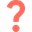
Проанализируйте и изложите содержательный смысл полученных результатов.

*# WRITE YOUR ANSWER*